In [5]:
# The repository is already open locally; no clone is needed.


In [6]:
%cd ..

c:\Users\syng8\Documents\Oregon-State-University-1A-forecasting-risk-of-harmful-algal-blooms-in-coastal-marine-ecosystems


In [7]:
import pandas as pd

train = pd.read_csv("data/processed/hab_train_seasonal.csv")
val = pd.read_csv("data/processed/hab_validation_seasonal.csv")

print("Training shape:", train.shape)
print("Validation shape:", val.shape)

print("\nTraining labels:")
print(train["target"].value_counts())

print("\nValidation labels:")
print(val["target"].value_counts())

Training shape: (154, 30)
Validation shape: (40, 30)

Training labels:
target
1    77
0    77
Name: count, dtype: int64

Validation labels:
target
0    20
1    20
Name: count, dtype: int64


In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Six environmental features from Copernicus
features = [
    "thetao_mean",
    "thetao_p95",
    "thetao_variance",
    "so_mean",
    "so_p95",
    "so_variance"
]

# Training data
X_train = train[features]
y_train = train["target"]

# Validation data
X_val = val[features]
y_val = val["target"]

print("Training features:", X_train.shape)
print("Validation features:", X_val.shape)
print("\nFeatures used:", features)

Training features: (154, 6)
Validation features: (40, 6)

Features used: ['thetao_mean', 'thetao_p95', 'thetao_variance', 'so_mean', 'so_p95', 'so_variance']


In [10]:
rf_baseline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_baseline.fit(X_train, y_train)

print("Random Forest baseline trained successfully!")

Random Forest baseline trained successfully!


In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

y_pred = rf_baseline.predict(X_val)
y_prob = rf_baseline.predict_proba(X_val)[:, 1]

print("Random Forest Baseline Results")
print("------------------------------")
print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, y_pred, zero_division=0), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, y_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, y_prob), 4))

Random Forest Baseline Results
------------------------------
Accuracy: 0.625
Precision: 0.619
Recall: 0.65
F1 Score: 0.6341
PR-AUC (Average Precision): 0.7096
ROC-AUC: 0.6375


In [12]:
# Add seasonal features to the original six environmental features
seasonal_features = features + [
    "sin_month",
    "cos_month"
]

X_train_seasonal = train[seasonal_features]
X_val_seasonal = val[seasonal_features]

rf_seasonal = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=3,
        random_state=42,
        class_weight="balanced"
    ))
])

rf_seasonal.fit(X_train_seasonal, y_train)

seasonal_pred = rf_seasonal.predict(X_val_seasonal)
seasonal_prob = rf_seasonal.predict_proba(X_val_seasonal)[:, 1]

print("Random Forest with Seasonal Features")
print("------------------------------------")
print("Accuracy:", round(accuracy_score(y_val, seasonal_pred), 4))
print("Precision:", round(precision_score(y_val, seasonal_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, seasonal_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_val, seasonal_pred, zero_division=0), 4))
print("PR-AUC:", round(average_precision_score(y_val, seasonal_prob), 4))
print("ROC-AUC:", round(roc_auc_score(y_val, seasonal_prob), 4))

Random Forest with Seasonal Features
------------------------------------
Accuracy: 0.575
Precision: 0.5652
Recall: 0.65
F1 Score: 0.6047
PR-AUC: 0.6746
ROC-AUC: 0.5975


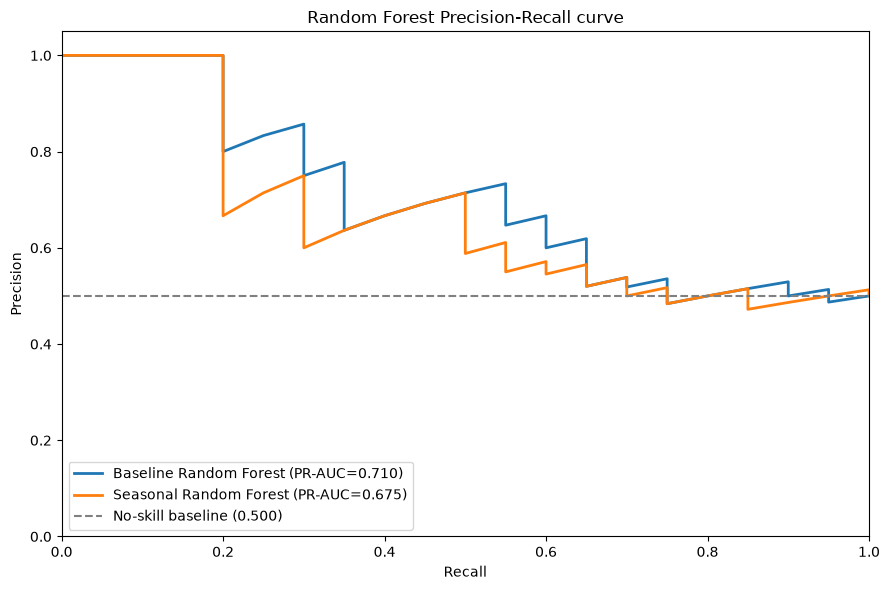

In [16]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

baseline_precision, baseline_recall, _ = precision_recall_curve(y_val, y_prob)
seasonal_precision, seasonal_recall, _ = precision_recall_curve(y_val, seasonal_prob)

fig, ax = plt.subplots(figsize=(9, 6))
ax.plot(
    baseline_recall,
    baseline_precision,
    linewidth=2,
    label=f"Baseline Random Forest (PR-AUC={average_precision_score(y_val, y_prob):.3f})",
)
ax.plot(
    seasonal_recall,
    seasonal_precision,
    linewidth=2,
    label=f"Seasonal Random Forest (PR-AUC={average_precision_score(y_val, seasonal_prob):.3f})",
)

positive_rate = y_val.mean()
ax.axhline(
    positive_rate,
    color="gray",
    linestyle="--",
    label=f"No-skill baseline ({positive_rate:.3f})",
)
ax.set_title("Random Forest Precision-Recall curve")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.05)
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()


Random Forest Results Summary

For Task #9, I trained and evaluated two Random Forest models to predict harmful algal bloom (HAB) events using Copernicus environmental data. The baseline model used six temperature and salinity features, while the second model included two additional cyclical seasonal features created in Task #5.

Both models achieved 60% accuracy. However, adding seasonal features improved recall from 60% to 70%, F1-score from 0.6000 to 0.6364, and PR-AUC from 0.7022 to 0.7202.

Feature importance analysis showed that salinity variance was the strongest predictor, followed by temperature-related features. The seasonal features had relatively low importance but may have helped the model identify additional HAB events.

These findings suggest that incorporating seasonal information may improve HAB detection. However, the dataset is relatively small and includes synthetic non-events, so further testing with more historical data and an independent test set is needed before drawing conclusions about real-world forecasting performance.

In [15]:
!pwd
!git branch --show-current
!git status

'pwd' is not recognized as an internal or external command,
operable program or batch file.


task9-random-forest
On branch task9-random-forest
Your branch is up to date with 'origin/task9-random-forest'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   notebooks/RandomForest.ipynb

no changes added to commit (use "git add" and/or "git commit -a")
